<a href="https://colab.research.google.com/github/codebyjuveria/AI-Mini-Projects./blob/main/LogisticRegressionMP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

import pandas as pd

import seaborn as sns

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/content/Diabetes_prediction.csv")

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [4]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
995,1,103.496355,41.059401,24.930299,43.675978,25.846062,0.455884,19.905419,0
996,1,60.714150,64.082842,24.689064,111.562745,19.464280,0.250560,44.421874,1
997,0,97.597727,64.122312,22.140339,108.138552,22.733052,0.761463,58.949800,1
998,0,66.775137,55.908797,24.885274,219.521484,31.819187,0.382877,46.928923,0
999,0,87.647268,69.111593,25.621266,134.335745,31.098746,0.605828,41.785889,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               1000 non-null   int64  
 1   Glucose                   1000 non-null   float64
 2   BloodPressure             1000 non-null   float64
 3   SkinThickness             1000 non-null   float64
 4   Insulin                   1000 non-null   float64
 5   BMI                       1000 non-null   float64
 6   DiabetesPedigreeFunction  1000 non-null   float64
 7   Age                       1000 non-null   float64
 8   Diagnosis                 1000 non-null   int64  
dtypes: float64(7), int64(2)
memory usage: 70.4 KB


In [6]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Diagnosis,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [12]:
# Replace the missing values using the correct column names

num_cols = ['Glucose', 'BMI', 'Age']

for col in num_cols:
  df[col] = df[col].fillna(df[col].median())

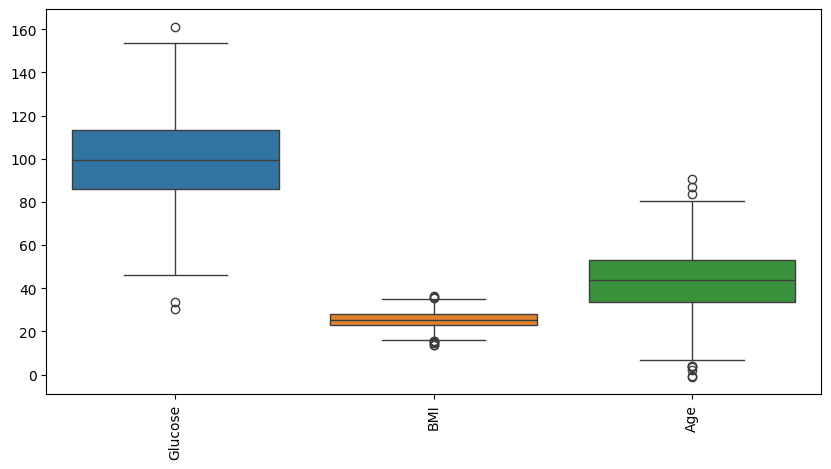

In [13]:
#outliers

plt.figure(figsize=(10,5))

sns.boxplot(data = df[num_cols])

plt.xticks(rotation=90)

plt.show()

In [14]:
# Remove Outliers

for col in num_cols:

  q1 = df[col].quantile(0.25)

  q3 = df[col].quantile(0.75)

  iqr = q3 - q1

  lower_bound = q1 - 1.5 * iqr

  upper_bound = q3 + 1.5 * iqr

  df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

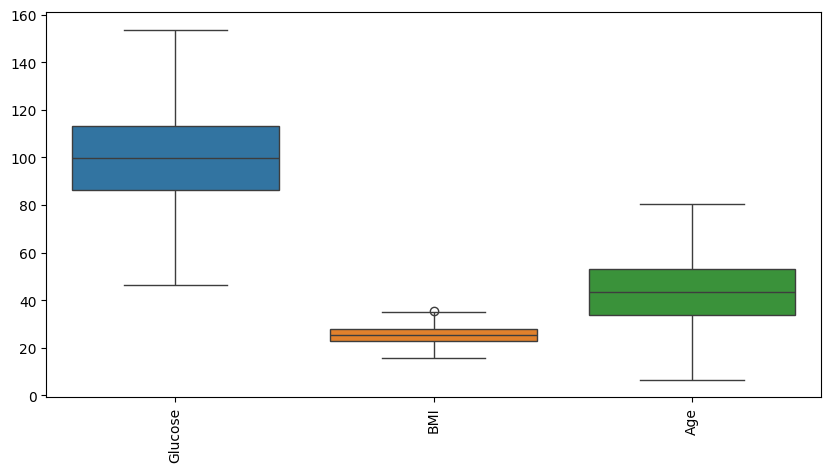

In [15]:
#outliers

plt.figure(figsize=(10,5))

sns.boxplot(data = df[num_cols])

plt.xticks(rotation=90)

plt.show()

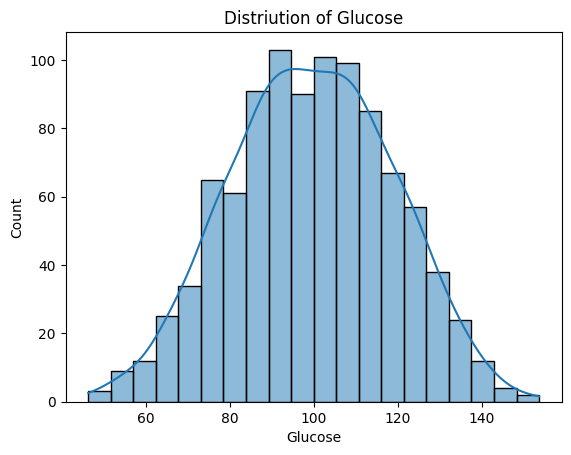

In [17]:
# Univariate
# Univariate analysis

import matplotlib.pyplot as plt

import seaborn as sns

sns.histplot(df['Glucose'],kde = True)

plt.title("Distriution of Glucose")

plt.show()


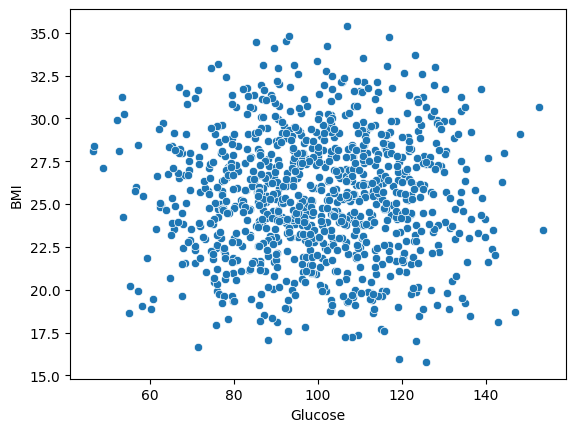

In [18]:
# Bivariate Analysis

sns.scatterplot(x = 'Glucose',y = 'BMI',data = df)

plt.show()

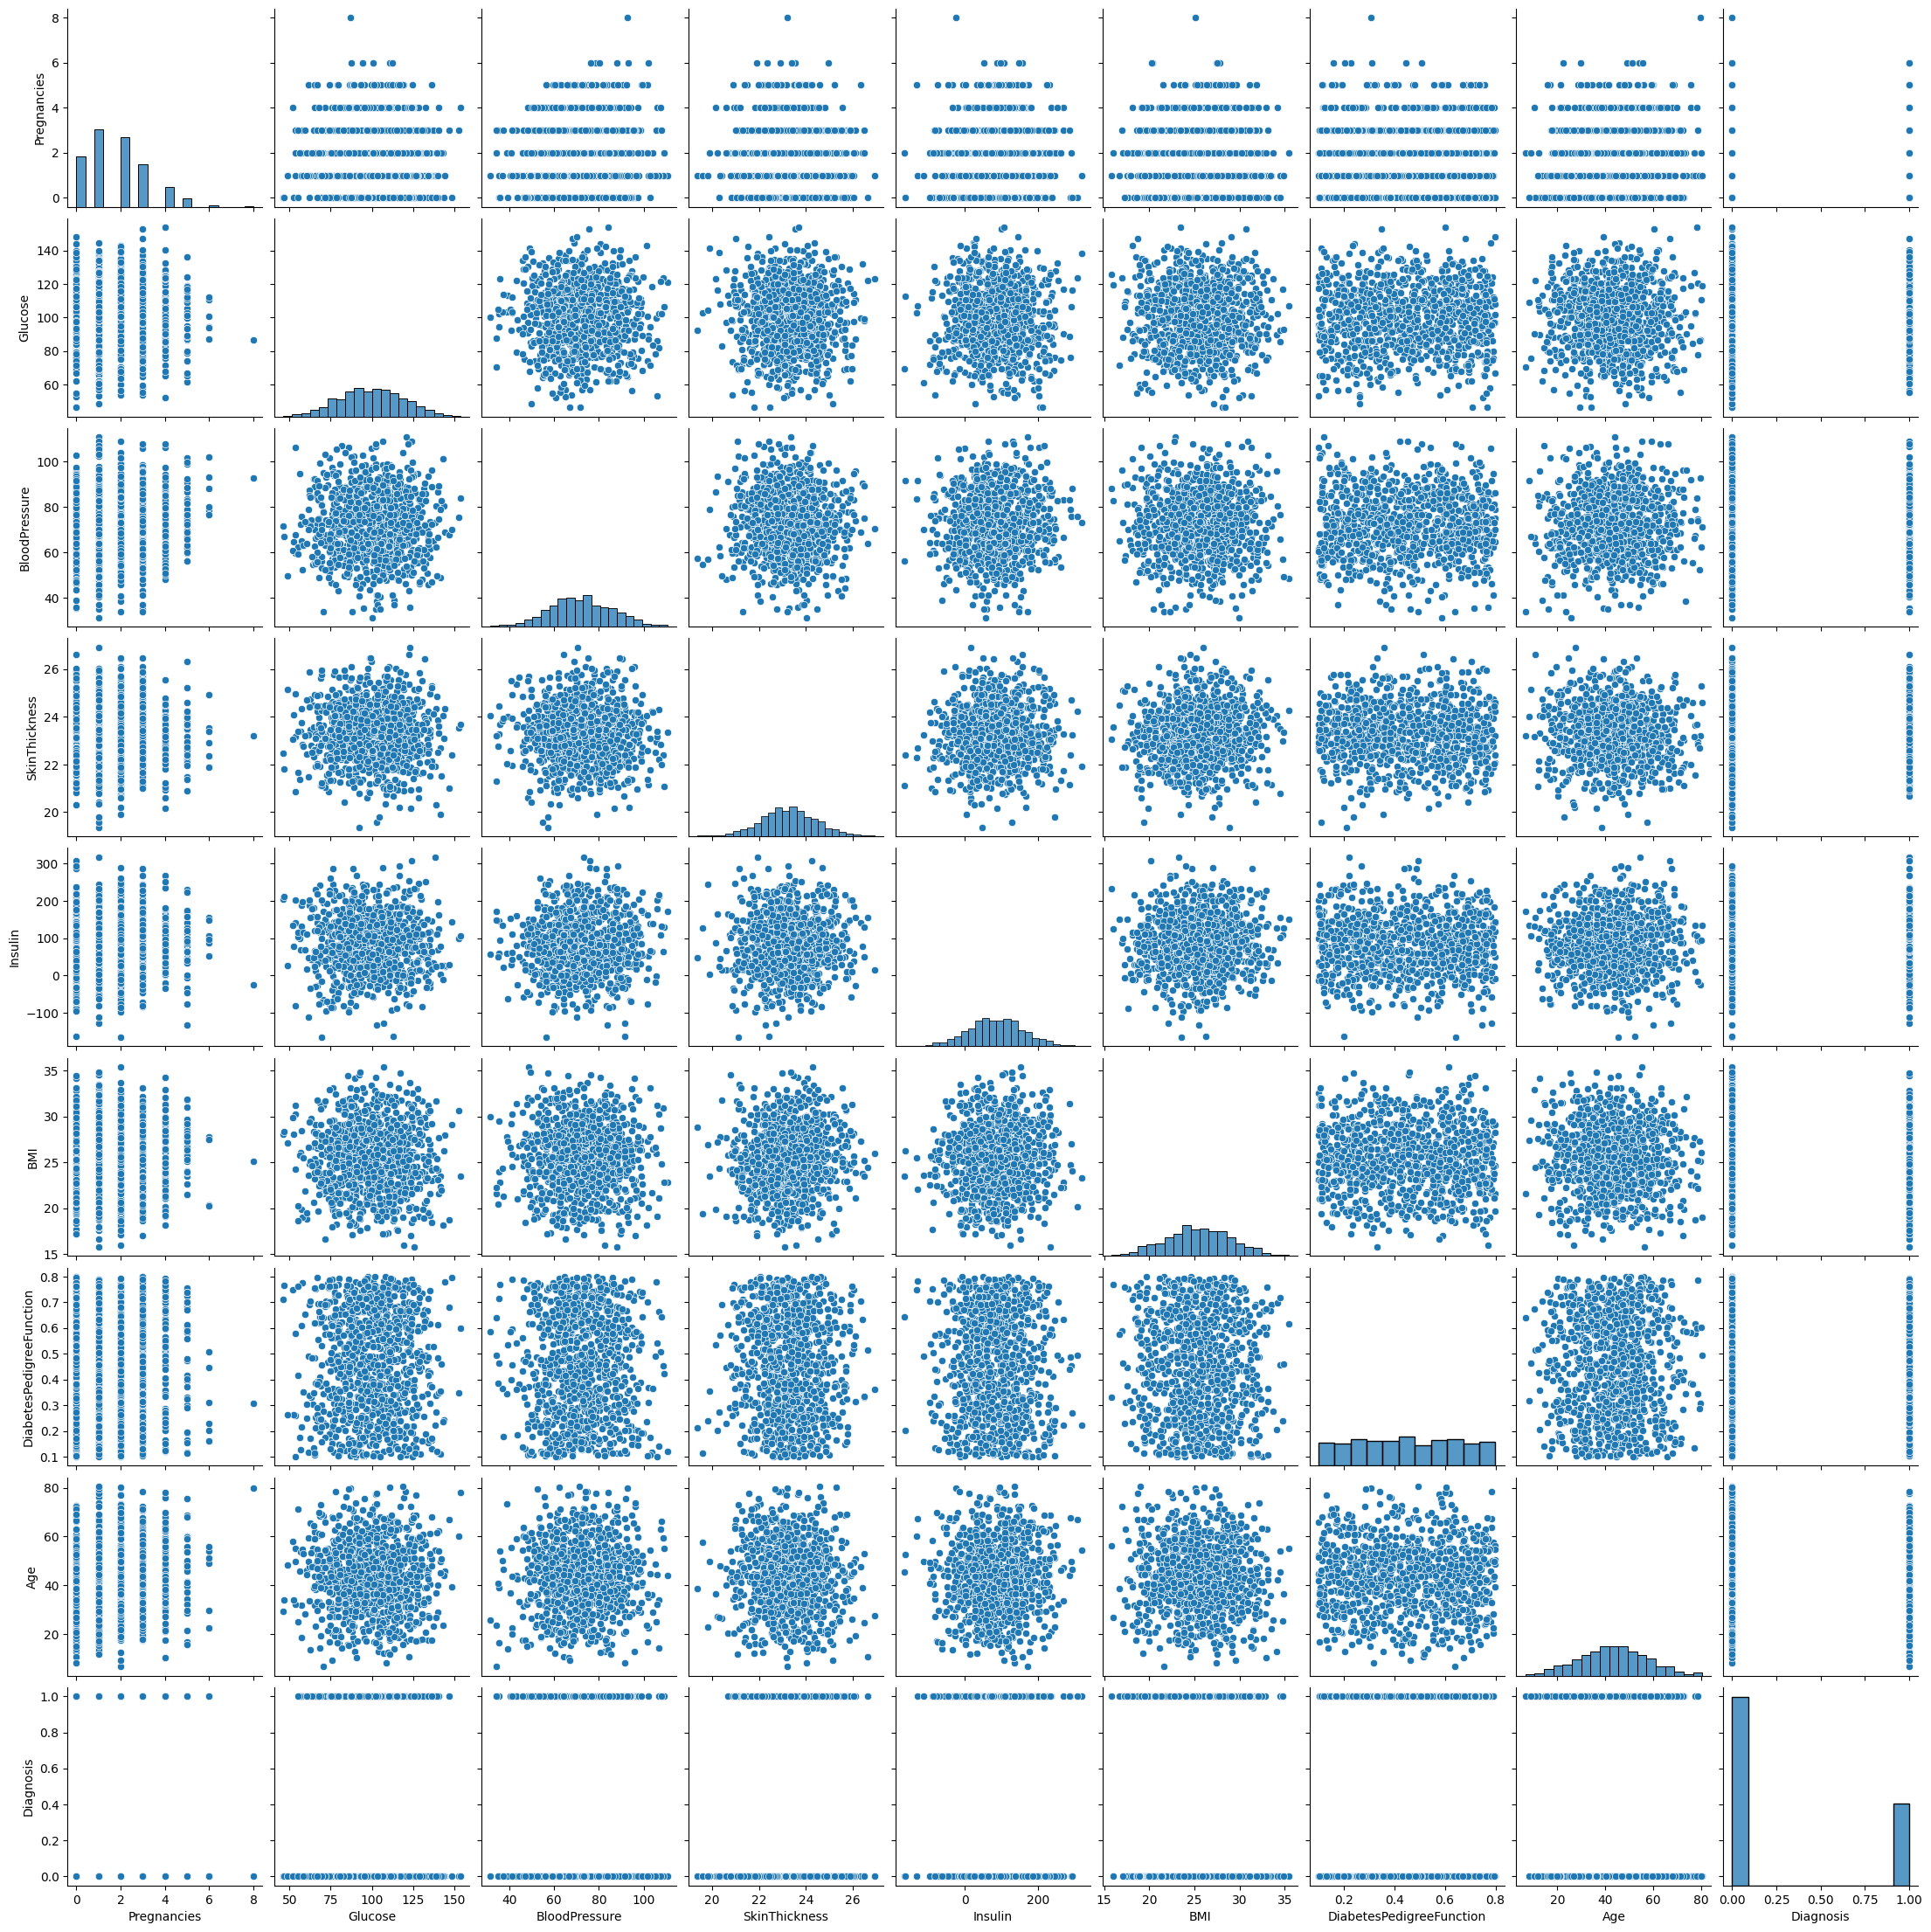

In [19]:
# Multivariate Analysis

sns.pairplot(df)

plt.show()

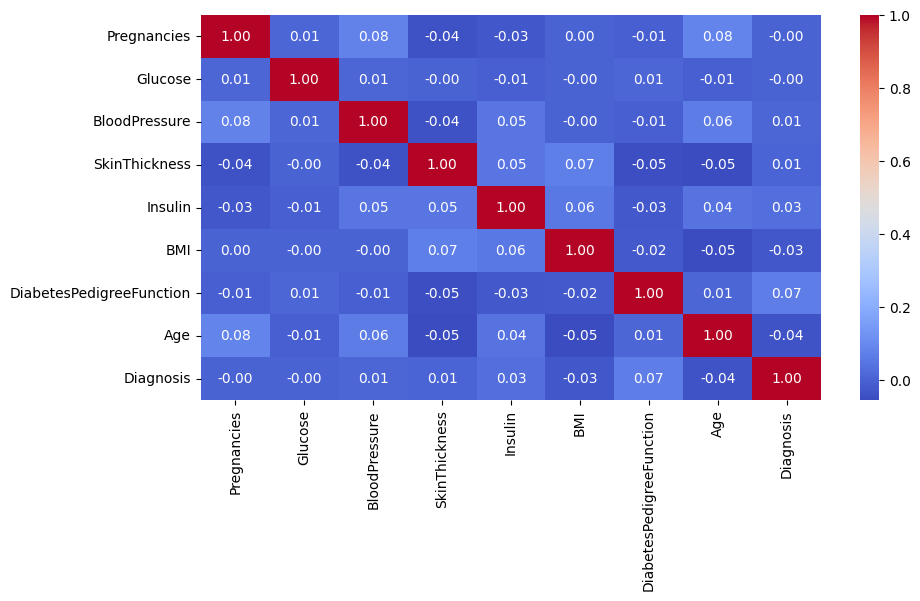

In [20]:
# Multi variate

plt.figure(figsize=(10,5))

sns.heatmap(df.corr(), annot=True,cmap = 'coolwarm',fmt ='.2f')

plt.show()

In [21]:
df.corr(numeric_only = True)['Glucose'].sort_values(ascending=True)

,Glucose
Age,-0.007834
Insulin,-0.006377
BMI,-0.000809
SkinThickness,-0.000597
Diagnosis,-0.000463
Pregnancies,0.007175
DiabetesPedigreeFunction,0.007390
BloodPressure,0.009668
Glucose,1.000000


In [48]:
print(df.columns.tolist())

['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Diagnosis']


In [49]:
# Separate X & Y

X = df.drop('Diagnosis', axis=1)

y = df['Diagnosis']

print(X.shape)

print(y.shape)

(982, 8)
(982,)


In [50]:
# Import Train_test_split

from sklearn.model_selection import train_test_split

In [51]:
# Split the dataset (stratify removed since y is a continuous variable)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [52]:
print(X.shape)

print(y.shape)

(982, 8)
(982,)


In [53]:
# Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [54]:
from sklearn.linear_model import LogisticRegression

In [55]:
model = LogisticRegression()

model.fit(X_train, y_train)

LogisticRegression()

In [56]:
y_pred = model.predict(X_test)

In [57]:
print(y_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [58]:
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})

results.head(10)

,Actual,Predicted
827,0,0
817,1,0
879,1,0
507,0,0
70,0,0
834,1,0
662,0,0
372,0,0
503,0,0
458,0,0


[[132   0]
 [ 65   0]]


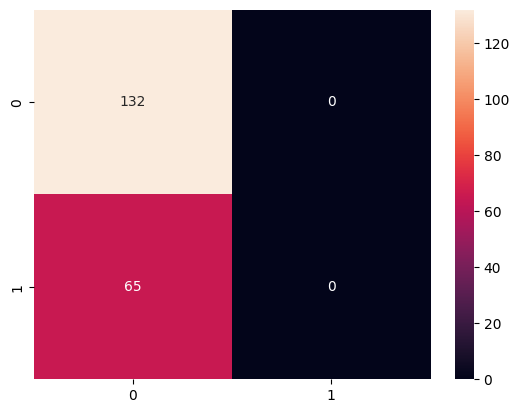

In [59]:
# Metrics

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)

print(cm)

# visualization

sns.heatmap(cm, annot=True, fmt='d')

plt.show()

In [60]:
# classification report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.67      1.00      0.80       132
           1       0.00      0.00      0.00        65

    accuracy                           0.67       197
   macro avg       0.34      0.50      0.40       197
weighted avg       0.45      0.67      0.54       197



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


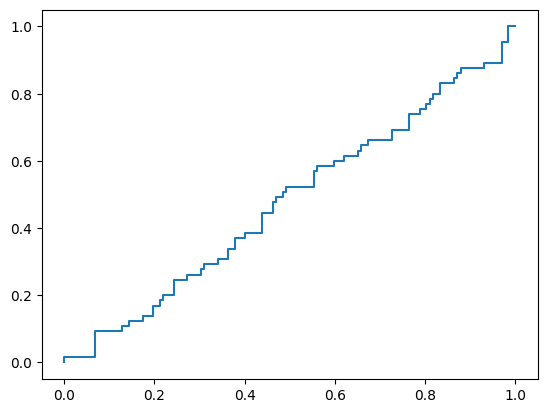

In [61]:
# ROC-AUC Curve

from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

#Roc curve

plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc_score(y_test, y_prob))

plt.show()

In [62]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob)

print("AUC:", round(auc,3))

AUC: 0.477
